In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df = pd.read_csv('data/train.csv')

In [37]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [38]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [39]:
print((df.isna().mean() * 100).sort_values(ascending=False))

Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Name            0.000000
Pclass          0.000000
Survived        0.000000
Sex             0.000000
Parch           0.000000
SibSp           0.000000
Fare            0.000000
Ticket          0.000000
dtype: float64


In [40]:
df["Survived"]

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

In [41]:
pd.crosstab(df["Survived"], df["Sex"], normalize=True)*100

Sex,female,male
Survived,,
0,9.090909,52.525253
1,26.150393,12.233446


In [42]:
df['Cabin'].isin(['C123']).value_counts()

Cabin
False    889
True       2
Name: count, dtype: int64

In [44]:
df['has_cabin'] = df["Cabin"].notna().astype(int)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,has_cabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0


In [45]:
df.groupby("has_cabin")["Survived"].mean()

has_cabin
0    0.299854
1    0.666667
Name: Survived, dtype: float64

In [46]:
print(df.groupby("has_cabin")["Survived"].agg(["mean", "count", "sum"]))

               mean  count  sum
has_cabin                      
0          0.299854    687  206
1          0.666667    204  136


In [47]:
print(pd.crosstab(df["Pclass"], df["has_cabin"]))

has_cabin    0    1
Pclass             
1           40  176
2          168   16
3          479   12


In [48]:
df["age_missing"] = df["Age"].isna().astype(int)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,has_cabin,age_missing
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0,0


In [49]:
df.groupby("age_missing")["Pclass"].mean()

age_missing
0    2.236695
1    2.598870
Name: Pclass, dtype: float64

In [50]:
print(pd.crosstab(df["Pclass"], df["age_missing"], normalize="index"))

age_missing         0         1
Pclass                         
1            0.861111  0.138889
2            0.940217  0.059783
3            0.723014  0.276986


In [51]:
df.groupby("Pclass")["Age"].median()

Pclass
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64

In [52]:
df["Age"].median()

np.float64(28.0)

In [53]:
df.groupby("Pclass")["Age"].mean()

Pclass
1    38.233441
2    29.877630
3    25.140620
Name: Age, dtype: float64

In [54]:
df1 = df.copy()
df2 = df.copy()

In [55]:
df1.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,has_cabin,age_missing
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0,0


In [56]:
df1["Age"] = df1["Age"].fillna(df["Age"].median())

In [57]:
df2["Age"] = df2["Age"].fillna(df2.groupby(["Sex", "Pclass"])["Age"].transform("median"))

In [58]:
df2.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
has_cabin        0
age_missing      0
dtype: int64

In [59]:
print(df["Age"].mean(), df["Age"].std())

29.69911764705882 14.526497332334042


In [60]:
print(df1["Age"].mean(), df1["Age"].std())

29.36158249158249 13.019696550973201


In [61]:
print(df2["Age"].mean(), df2["Age"].std())

29.11242424242424 13.304424074688162


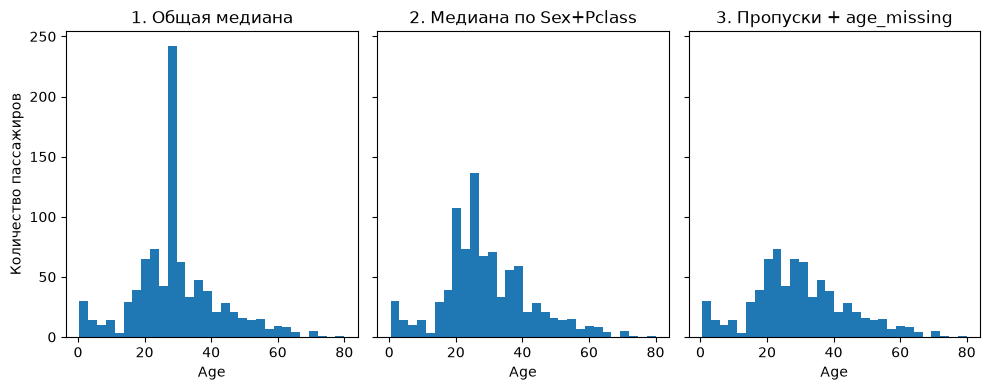

In [65]:
age1 = df["Age"].fillna(df["Age"].median())

age2 = df["Age"].fillna(df.groupby(["Sex", "Pclass"])["Age"].transform("median"))

df["age_missing"] = df["Age"].isna().astype(int)
age3 = df["Age"]

variants = {
    "1. Общая медиана": age1,
    "2. Медиана по Sex+Pclass": age2,
    "3. Пропуски + age_missing": age3,
}

fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharey=True)

for ax, (name, age) in zip(axes, variants.items()):
    ax.hist(age.dropna(), bins=30)
    ax.set_title(name)
    ax.set_xlabel("Age")

axes[0].set_ylabel("Количество пассажиров")
plt.tight_layout()
plt.show()

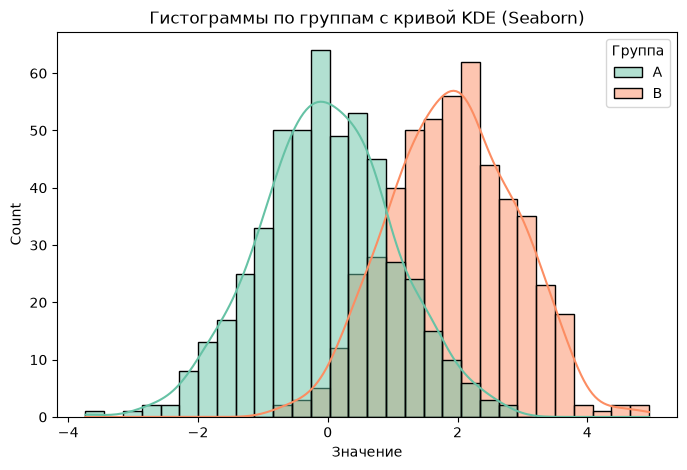

In [32]:

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df, x='Значение', hue='Группа', kde=True, bins=30, palette='Set2'
)

plt.title('Гистограммы по группам с кривой KDE (Seaborn)')
plt.show()


In [ ]:
def clean_titatic(df):
    df_clean = df.copy()
    df_clean['age_missing'] = df_clean["Age"].isna().astype(int)
    df_clean["has_cabin"] = df_clean["Cabin"].notna().astype(int)